# 📝 Lecture 10 Activity Notebook: Sentiment Analysis
## AA640: Data Analytics and Text Mining
### Bryant University | Prof. Gianluca Brero

---

**IMPORTANT:** *Before starting, save a copy to your Drive via `File > "Save a copy in Drive"`*

### 🎯 Estimated Time: 90 Minutes

#### In-Class Schedule

| Time | Clock | Block |
|------|-------|-------|
| 30 min | 6:30pm | Lecture: Lexicon-Based Sentiment |
| 20 min | 7:00pm | **Activity 1** — Score debate speeches with Opinion Lexicon |
| 30 min | 7:20pm | Lecture: VADER & Emotion Analysis |
| 30 min | 7:50pm | Break + Quiz |
| 20 min | 8:20pm | **Activity 2** — VADER + NRC analysis by candidate |
| 30 min | 8:40pm | Open time — questions, finish notebook |

#### After-Class Activities (~30 min)
*Complete these on your own after lecture.*

| Activity | Topic | Time |
|----------|-------|------|
| Activity 3 | Fear Emotion by Party | ~15 min |
| Activity 4 | Full Emotion Profile by Candidate | ~15 min |

### ⚙️ How to Use This Notebook
1. **Read** each section carefully
2. **Run** the example cells first to see how things work
3. **Complete** the activities marked with 📝
4. **Check** your answers against the expected output

> 💡 **Tip:** If you get stuck, re-read the example cell right above the activity — the pattern is always there!

## Setup: Import Libraries

In [ ]:
# Install required packages (run this cell first)
# Pin nrclex to 3.0.0 — later versions changed the API and break NRCLex(text)
!pip install vaderSentiment "nrclex==3.0.0" --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 396.4/396.4 kB 7.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 8.9 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

# NLP tools
import nltk
from nltk.corpus import stopwords, opinion_lexicon
from nltk.tokenize import word_tokenize
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from nrclex import NRCLex

# Download NLTK resources
nltk.download('stopwords', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('opinion_lexicon', quiet=True)

print("Setup complete!")

Setup complete!


---
## Loading and Cleaning the Debate Data

We will work with transcripts from the **2016 US Presidential Primary Debates**. Each row is a single statement made by a candidate during a debate.

**To load the file in Colab:**
1. Click the **folder icon** on the left sidebar.
2. Click the **upload button** (the icon with an upward arrow).
3. Select `primary_debates_cleaned.csv` from your computer.
4. Then run the cell below.

In [ ]:
# Load the debate data
raw_debates = pd.read_csv('primary_debates_cleaned.csv')
print(f"Dataset: {raw_debates.shape[0]} rows, {raw_debates.shape[1]} columns")
raw_debates.head()

Dataset: 13257 rows, 7 columns


,Line,Speaker,Text,Date,Party,Location,URL
0,1,Woodruff,"Good evening, and thank you. We are happy to w...",2/11/16,Democratic,"Milwaukee, Wisconsin",http://www.presidency.ucsb.edu/ws/index.php?pi...
1,2,Ifill,We want to also extend our warm thanks to Milw...,2/11/16,Democratic,"Milwaukee, Wisconsin",http://www.presidency.ucsb.edu/ws/index.php?pi...
2,3,AUDIENCE,(APPLAUSE),2/11/16,Democratic,"Milwaukee, Wisconsin",http://www.presidency.ucsb.edu/ws/index.php?pi...
3,4,Woodruff,"Welcome, Senator, great to see you. And former...",2/11/16,Democratic,"Milwaukee, Wisconsin",http://www.presidency.ucsb.edu/ws/index.php?pi...
4,5,AUDIENCE,(APPLAUSE),2/11/16,Democratic,"Milwaukee, Wisconsin",http://www.presidency.ucsb.edu/ws/index.php?pi...


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Filter to Candidate Statements Only

The dataset includes moderators and audience reactions. We only want actual candidates.

In [ ]:
# Define candidates
candidates = ['Bush', 'Carson', 'Chafee', 'Christie', 'Clinton', 'Cruz', 'Fiorina',
              'Gilmore', 'Graham', 'Huckabee', 'Jindal', 'Kasich', "O'Malley",
              'Pataki', 'Paul', 'Perry', 'Rubio', 'Sanders', 'Santorum', 'Trump',
              'Walker', 'Webb']

# Filter to candidate statements and keep relevant columns
debates = raw_debates[raw_debates['Speaker'].isin(candidates)].copy()
debates['Party'] = debates['Party'].replace('Republican Undercard', 'Republican')
debates = debates[['Speaker', 'Party', 'Text']].copy()

print(f"Candidate statements: {len(debates)}")
print(f"\nParties: {debates['Party'].unique()}")
print(f"\nSpeakers: {debates['Speaker'].nunique()} candidates")
debates.head()

Candidate statements: 5768

Parties: ['Democratic' 'Republican']

Speakers: 22 candidates


,Speaker,Party,Text
6,Clinton,Democratic,Thank you.
10,Sanders,Democratic,"Well, Gwen and Judy, thank you very much for h..."
14,Clinton,Democratic,I'm running for president to knock down all th...
20,Sanders,Democratic,"Well, to put that in a context, Judy, I think ..."
22,Sanders,Democratic,"... Of course there will be a limit, but when ..."


### Clean and Tokenize the Text

Before analyzing sentiment, we need to clean and tokenize the text. This is the same cleaning pipeline from Lecture 7:
1. Lowercase everything
2. Remove punctuation
3. Split into individual words (tokens)
4. Remove stop words

In [ ]:
stop_words = set(stopwords.words('english'))

def clean_text(text):
    """Clean and tokenize text: lowercase, remove punctuation, remove stop words"""
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)
    tokens = word_tokenize(text)
    tokens = [word for word in tokens if word not in stop_words and word.isalpha()]
    return tokens

# Apply cleaning
debates['tokens'] = debates['Text'].apply(clean_text)

print("Example tokens:")
print(debates['tokens'].iloc[1][:10])

Example tokens:
['well', 'gwen', 'judy', 'thank', 'much', 'hosting', 'event', 'pbs', 'thank', 'nine']


---
# 📌 IN-CLASS ACTIVITIES

Complete these sections during class time. Each activity has demo cells above it — run the demos first, then work on the 📝 activity.

---

## Approach 1: The Opinion Lexicon

The **Opinion Lexicon** is a list of ~6,800 words that have been labeled as either **positive** or **negative** by human experts.

The idea is simple:
- For each word in a speech, check if it's in the positive or negative list
- Add +1 for positive words, -1 for negative words
- The total is the **sentiment score**

### Demo: Building the Sentiment Scoring Function

In [ ]:
# Load the positive and negative word sets
pos_words = set(opinion_lexicon.positive())
neg_words = set(opinion_lexicon.negative())

print(f"Positive words: {len(pos_words)}")
print(f"Negative words: {len(neg_words)}")
print(f"\nSample positive: {list(pos_words)[:5]}")
print(f"Sample negative: {list(neg_words)[:5]}")

Positive words: 2006
Negative words: 4783

Sample positive: ['excellency', 'halcyon', 'smiling', 'monumental', 'cleared']
Sample negative: ['dope', 'dizzing', 'tout', 'fatalistically', 'discourage']


In [ ]:
def sentiment_score(tokens):
    """Score a list of tokens: +1 per positive word, -1 per negative word"""
    score = 0
    for word in tokens:
        if word in pos_words:
            score += 1
        elif word in neg_words:
            score -= 1
    return score

# Test it on a simple example
test_tokens = ['great', 'product', 'terrible', 'service']
print(f"Tokens: {test_tokens}")
print(f"Score: {sentiment_score(test_tokens)}")
print("  'great' = +1, 'terrible' = -1, others = 0 => total = 0")

Tokens: ['great', 'product', 'terrible', 'service']
Score: 0
  'great' = +1, 'terrible' = -1, others = 0 => total = 0


### Demo: Applying the Score to the Debate Data

In [ ]:
# Apply the sentiment function to every speech
debates['lexicon_score'] = debates['tokens'].apply(sentiment_score)

# Look at a few examples
print("Sample scores:")
print(debates[['Speaker', 'Text', 'lexicon_score']].head(10).to_string())

Sample scores:
    Speaker                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              

---
## Activity 1: Opinion Lexicon Scoring (~20 min)

*You are working as a data analyst for a political consulting firm. Your boss says: "We have transcripts from the 2016 presidential primary debates. I need you to score each speech using the Opinion Lexicon and compare the two parties. Give me charts so I can present this to the client."*

### 📝 Activity 1a: Average Sentiment by Party

Compute the **average Opinion Lexicon score** for each party and create a **bar chart**.

Steps:
1. Use `debates.groupby('Party')['lexicon_score'].mean()` to get the averages
2. Create a bar chart with `plt.bar()`
3. Add a title: "Average Sentiment Score by Party (Opinion Lexicon)"
4. Add axis labels

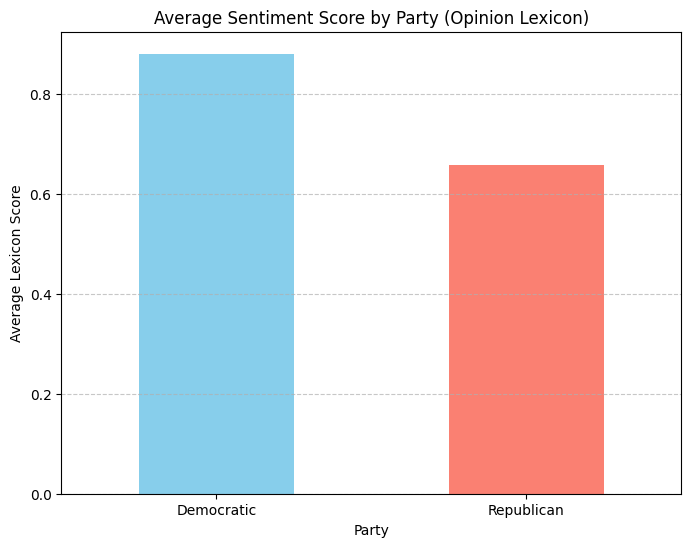

In [ ]:
import matplotlib.pyplot as plt

# 1. Compute average lexicon_score by party
average_sentiment_by_party = debates.groupby('Party')['lexicon_score'].mean()

# 2. Create a bar chart
plt.figure(figsize=(8, 6))
average_sentiment_by_party.plot(kind='bar', color=['skyblue', 'salmon'])

# 3. Add a title
plt.title('Average Sentiment Score by Party (Opinion Lexicon)')

# 4. Add axis labels
plt.xlabel('Party')
plt.ylabel('Average Lexicon Score')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### 📝 Activity 1b: Top 15 Sentiment Words

Find the **15 most frequent sentiment words** across all speeches and create a horizontal bar chart showing positive words going right and negative words going left.

Steps:
1. Create a lexicon DataFrame from `opinion_lexicon`
2. Flatten all tokens into a single DataFrame of words
3. Merge (join) with the lexicon to keep only sentiment words
4. Count occurrences, take top 15
5. Plot with `sns.barplot()`

/tmp/ipykernel_1147/2050101109.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='signed_count', y='word', data=top_15_sentiment_words, palette='coolwarm')


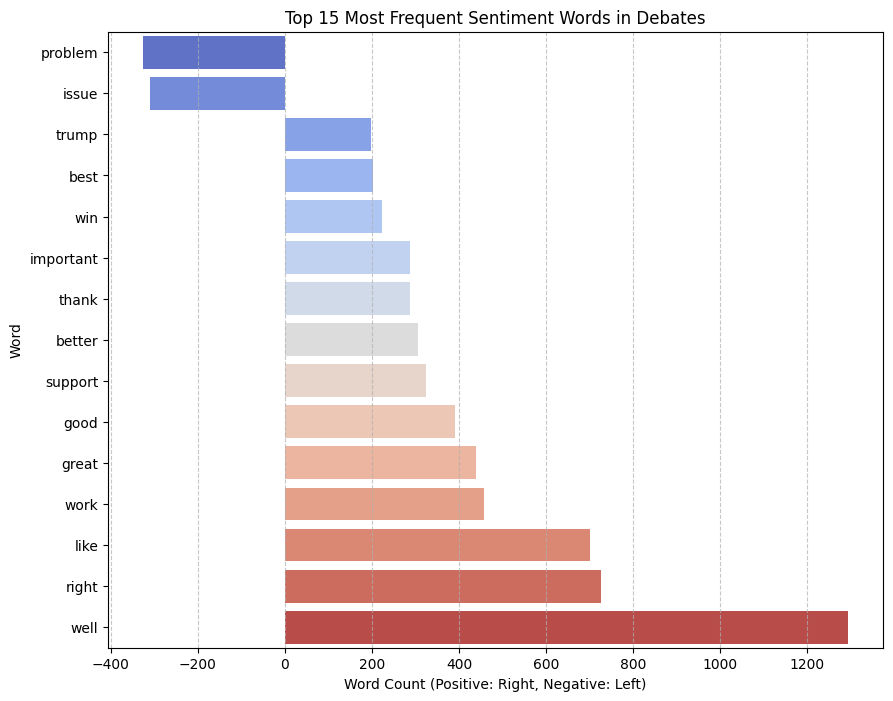

In [ ]:
# 1. Create a lexicon DataFrame from opinion_lexicon
lexicon_df = pd.DataFrame({
    'word': list(pos_words) + list(neg_words),
    'sentiment': ['positive'] * len(pos_words) + ['negative'] * len(neg_words)
})

# 2. Flatten all tokens into a single DataFrame of words
all_tokens = debates['tokens'].explode().to_frame(name='word')

# 3. Merge (join) with the lexicon to keep only sentiment words
sentiment_words_in_debates = pd.merge(
    all_tokens, lexicon_df, on='word',
    how='inner'
)

# 4. Count occurrences
sentiment_word_counts = sentiment_words_in_debates['word'].value_counts().reset_index()
sentiment_word_counts.columns = ['word', 'count']

# Join with sentiment labels
sentiment_word_counts = pd.merge(sentiment_word_counts, lexicon_df, on='word', how='left')

# Calculate signed count for plotting (positive words get positive counts, negative words get negative counts)
sentiment_word_counts['signed_count'] = sentiment_word_counts.apply(
    lambda row: row['count'] if row['sentiment'] == 'positive' else -row['count'], axis=1
)

# Take top 15 by absolute count
top_15_sentiment_words = sentiment_word_counts.loc[sentiment_word_counts['signed_count'].abs().nlargest(15).index].sort_values(by='signed_count', ascending=True)

# 5. Plot with sns.barplot()
plt.figure(figsize=(10, 8))
sns.barplot(x='signed_count', y='word', data=top_15_sentiment_words, palette='coolwarm')
plt.title('Top 15 Most Frequent Sentiment Words in Debates')
plt.xlabel('Word Count (Positive: Right, Negative: Left)')
plt.ylabel('Word')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

### 📝 Activity 1c: Interpret the Results

Look at your bar chart from 1b and answer these questions in the cell below:

1. Are the top positive words truly expressing positive sentiment, or are some of them just common words? Give an example.
2. What does this tell you about the limitations of simple word-counting approaches?

**Your answers here:**

1.  Looking at the top positive words ('well', 'right', 'like', 'work', 'great', 'good'), some are genuinely positive ('great', 'good'), but others like 'well', 'right', and 'like' are very common words that don't always express strong positive sentiment. For example, 'well' can be a discourse marker (e.g., "Well, I think...") rather than conveying a positive feeling. 'Right' can mean correct, or refer to a political right, which are not necessarily emotional.

2.  This tells us that simple word-counting approaches, like the Opinion Lexicon, have limitations. They can be overly simplistic because they treat every instance of a word as having the same sentiment value, regardless of context. They often don't account for nuances like negation, sarcasm, or words that are frequently used but carry little to no sentiment in certain contexts (e.g., filler words or words with multiple meanings). This can lead to a less accurate overall sentiment score.

---
## Approach 2: VADER (Context-Aware Sentiment)

**VADER** (Valence Aware Dictionary and sEntiment Reasoner) improves on simple lexicons by understanding:
- **Negation**: "not good" → negative
- **Intensifiers**: "very good" → more positive than "good"
- **Punctuation**: "Good!!!" → more positive than "Good"
- **Capitalization**: "GREAT" → more positive than "great"

It returns a **compound score** from -1 (most negative) to +1 (most positive).

### Demo: VADER in Action

In [ ]:
# Initialize the VADER analyzer
analyzer = SentimentIntensityAnalyzer()

# Try a few examples to see how VADER handles context
examples = [
    "This is great",
    "This is not great",
    "This is GREAT!!!",
    "This is very very great",
    "The food was good but the service was terrible"
]

for text in examples:
    scores = analyzer.polarity_scores(text)
    print(f"\"{text}\"")
    print(f"  Compound: {scores['compound']:.3f}  (pos={scores['pos']:.2f}, neg={scores['neg']:.2f})")
    print()

"This is great"
  Compound: 0.625  (pos=0.67, neg=0.00)

"This is not great"
  Compound: -0.510  (pos=0.00, neg=0.52)

"This is GREAT!!!"
  Compound: 0.772  (pos=0.74, neg=0.00)

"This is very very great"
  Compound: 0.688  (pos=0.54, neg=0.00)

"The food was good but the service was terrible"
  Compound: -0.494  (pos=0.15, neg=0.32)



### Demo: Applying VADER to the Debates

In [ ]:
# Apply VADER to the raw text (not the cleaned tokens!)
# VADER needs punctuation and capitalization to work properly
debates['vader_score'] = debates['Text'].apply(
    lambda text: analyzer.polarity_scores(text)['compound'])

# Compare VADER scores by party
vader_by_party = debates.groupby('Party')['vader_score'].mean()
print("Average VADER Compound Score by Party:")
print(vader_by_party)
print()

# Compare with Opinion Lexicon
lexicon_by_party = debates.groupby('Party')['lexicon_score'].mean()
print("Average Opinion Lexicon Score by Party:")
print(lexicon_by_party)

Average VADER Compound Score by Party:
Party
Democratic    0.222973
Republican    0.135564
Name: vader_score, dtype: float64

Average Opinion Lexicon Score by Party:
Party
Democratic    0.880294
Republican    0.657993
Name: lexicon_score, dtype: float64


---
## Approach 3: NRC Emotion Lexicon

The **NRC Emotion Lexicon** goes beyond positive/negative and maps words to 8 emotions: *anger, anticipation, disgust, fear, joy, sadness, surprise, trust*.

This lets us ask richer questions: Are candidates using more *fear* language or *joy* language?

### Demo: NRC Emotion Labels

In [ ]:
# See what emotions the NRC lexicon assigns to a few words
sample_words = ['money', 'war', 'vote', 'love', 'attack']

for word in sample_words:
    emo = NRCLex(word)
    emotions = list(emo.raw_emotion_scores.keys())
    print(f"'{word}' -> {emotions}")

'money' -> ['anger', 'anticipation', 'joy', 'positive', 'surprise', 'trust']
'war' -> ['fear', 'negative']
'vote' -> ['anger', 'anticipation', 'joy', 'negative', 'positive', 'sadness', 'surprise', 'trust']
'love' -> ['joy', 'positive']
'attack' -> ['anger', 'fear', 'negative']


### Demo: Building the NRC Emotion Lookup Table

In [ ]:
# Get all unique words from the debate
all_debate_words = set(word for tokens in debates['tokens'] for word in tokens)
print(f"Unique words to look up: {len(all_debate_words)}")

# Build NRC emotion labels for each word (this may take a minute)
nrc_emotions = []
for word in all_debate_words:
    emo = NRCLex(word)
    for emotion in emo.raw_emotion_scores:
        nrc_emotions.append((word, emotion))

nrc_df = pd.DataFrame(nrc_emotions, columns=["word", "emotion"])
print(f"\nNRC lookup table: {len(nrc_df)} word-emotion pairs")
print(f"Emotions available: {nrc_df['emotion'].unique()}")

Unique words to look up: 11199

NRC lookup table: 5363 word-emotion pairs
Emotions available: ['joy' 'positive' 'anger' 'negative' 'sadness' 'fear' 'anticipation'
 'trust' 'disgust' 'surprise']


### Demo: Counting Joy Words by Party

In [ ]:
# Get the set of words associated with "joy"
joy_set = set(nrc_df[nrc_df['emotion'] == 'joy']['word'])
print(f"Joy words in lexicon: {len(joy_set)}")
print(f"Sample: {list(joy_set)[:8]}")
print()

# Count how many joy words appear in each speech
debates['joy_count'] = debates['tokens'].apply(
    lambda tokens: sum(1 for word in tokens if word in joy_set))

# Average joy words per speech by party
joy_by_party = debates.groupby('Party')['joy_count'].mean()
print("Average joy words per speech by party:")
print(joy_by_party)

Joy words in lexicon: 301
Sample: ['kind', 'favorable', 'expedient', 'friend', 'god', 'smiling', 'loving', 'utopian']

Average joy words per speech by party:
Party
Democratic    1.175042
Republican    1.067551
Name: joy_count, dtype: float64


---
## Activity 2: VADER + NRC Emotions (~20 min)

*Your boss is back: "The lexicon analysis was helpful, but I need something more nuanced. Run VADER and the NRC emotion analysis on the two major candidates — Clinton and Trump. Give me comparison charts so I can present to the team."*

### 📝 Activity 2a: VADER Comparison — Opinion Lexicon vs. VADER

Create a **grouped bar chart** comparing the average Opinion Lexicon score and the average VADER score for each party (side by side).

Steps:
1. Compute average `lexicon_score` and `vader_score` by party
2. Use `pd.DataFrame` to organize the data for plotting
3. Use `df.plot(kind='bar')` or `plt.bar()` with grouped bars

*Hint: Create a DataFrame with Party as index and two columns (Lexicon, VADER), then call `.plot(kind='bar')`*

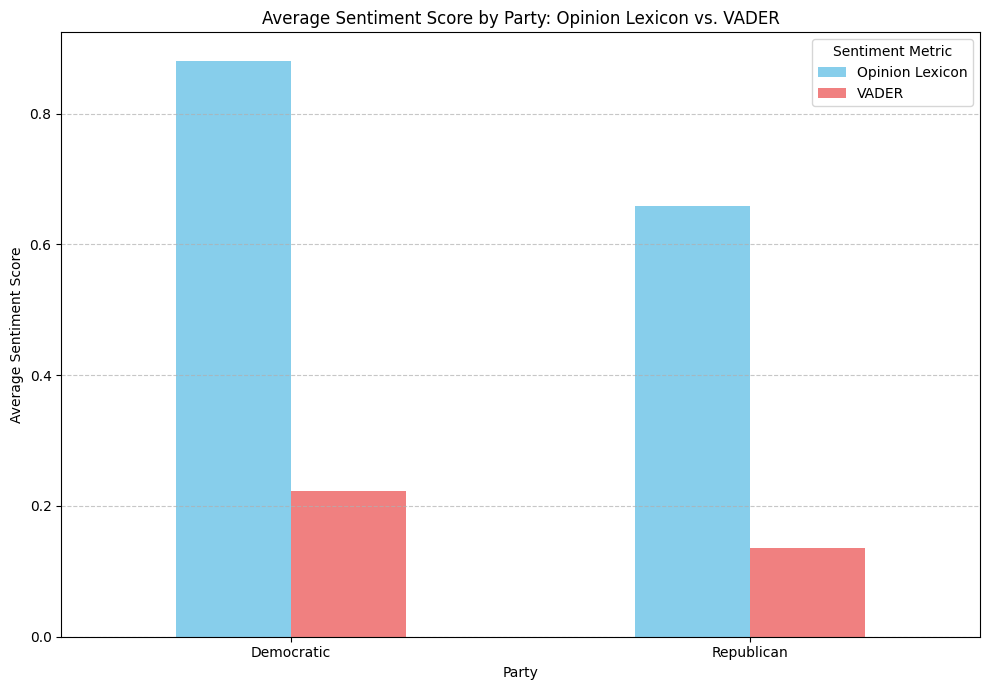

In [ ]:
import matplotlib.pyplot as plt

# 1. Compute average lexicon_score and vader_score by party
# These were already computed in previous cells as 'lexicon_by_party' and 'vader_by_party'

# 2. Use pd.DataFrame to organize the data for plotting
comparison_df = pd.DataFrame({
    'Opinion Lexicon': lexicon_by_party,
    'VADER': vader_by_party
})

# 3. Use df.plot(kind='bar') to create a grouped bar chart
fig, ax = plt.subplots(figsize=(10, 7))
comparison_df.plot(kind='bar', ax=ax, rot=0, color=['skyblue', 'lightcoral'])

# Add title and labels
plt.title('Average Sentiment Score by Party: Opinion Lexicon vs. VADER')
plt.xlabel('Party')
plt.ylabel('Average Sentiment Score')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Sentiment Metric')
plt.tight_layout()
plt.show()

### 📝 Activity 2b: VADER Scores for Clinton vs. Trump

Filter the data to just **Clinton** and **Trump**, then create a **bar chart** of their average VADER compound scores.

Steps:
1. Filter: `debates[debates['Speaker'].isin(['Clinton', 'Trump'])]`
2. Group by Speaker and compute mean VADER score
3. Plot a bar chart

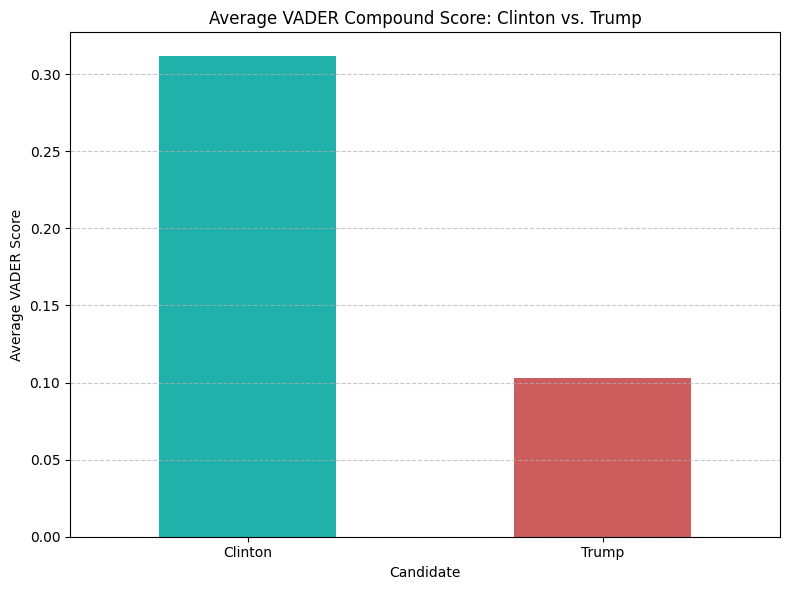

In [ ]:
# Activity 2b: Bar chart of VADER scores for Clinton vs Trump
# Expected output: a bar chart with one bar per candidate

# 1. Filter to just Clinton and Trump
clinton_trump_debates = debates[debates['Speaker'].isin(['Clinton', 'Trump'])]

# 2. Group by Speaker and compute mean VADER score
average_vader_clinton_trump = clinton_trump_debates.groupby('Speaker')['vader_score'].mean()

# 3. Plot a bar chart
plt.figure(figsize=(8, 6))
average_vader_clinton_trump.plot(kind='bar', color=['lightseagreen', 'indianred'])

# Add title and labels
plt.title('Average VADER Compound Score: Clinton vs. Trump')
plt.xlabel('Candidate')
plt.ylabel('Average VADER Score')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 📝 Activity 2c: Joy and Fear by Candidate (Clinton vs. Trump)

Count the average number of **joy** and **fear** words per speech for Clinton and Trump. Create a **grouped bar chart** comparing both emotions.

Steps:
1. Build a fear word set (same pattern as the joy demo)
2. Count joy and fear words per speech for Clinton and Trump
3. Create a grouped bar chart

*Hint: Follow the same pattern as the joy demo, but also do it for fear*

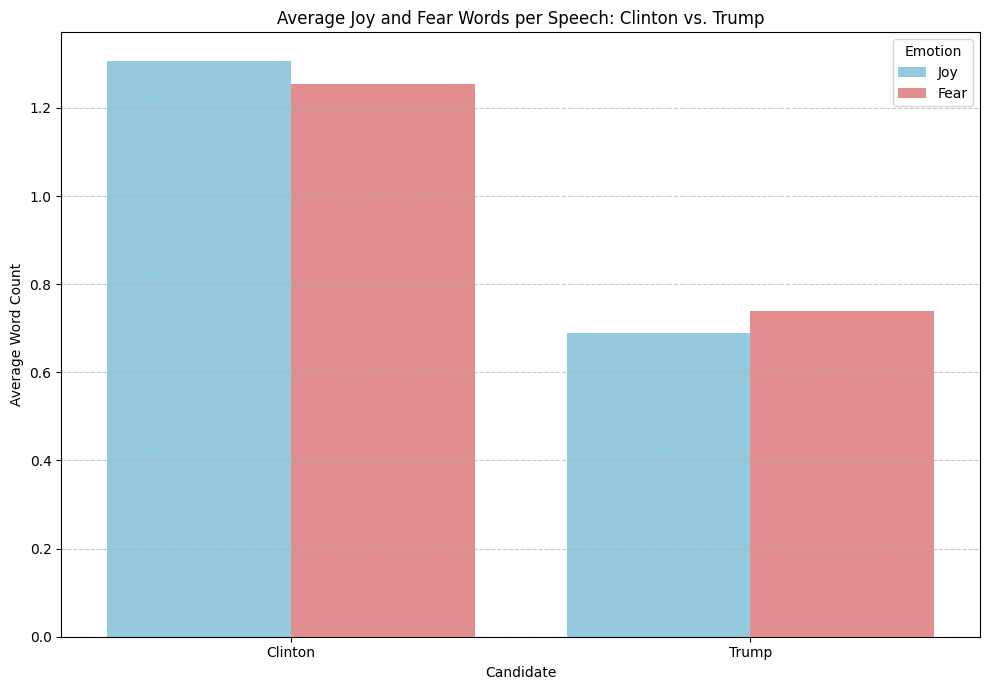

In [ ]:
# Activity 2c: Grouped bar chart of joy and fear words for Clinton vs Trump
# Expected output: a grouped bar chart with one group per candidate,
#   each group containing two bars (Joy, Fear)

# 1. Build a fear word set (same pattern as the joy demo)
fear_set = set(nrc_df[nrc_df['emotion'] == 'fear']['word'])

# Ensure 'fear_count' column exists in debates DataFrame
# (Calculate fear words for all speeches first, if not already done)
if 'fear_count' not in debates.columns:
    debates['fear_count'] = debates['tokens'].apply(
        lambda tokens: sum(1 for word in tokens if word in fear_set))

# 2. Count joy and fear words per speech for Clinton and Trump
clinton_trump_emotions = debates[debates['Speaker'].isin(['Clinton', 'Trump'])].copy()

# Group by Speaker and compute mean joy and fear scores
avg_emotions_by_candidate = clinton_trump_emotions.groupby('Speaker')[['joy_count', 'fear_count']].mean().reset_index()

# Reshape the data for plotting with seaborn
avg_emotions_melted = avg_emotions_by_candidate.melt(
    id_vars='Speaker',
    var_name='Emotion',
    value_name='Average Count'
)

# Map the emotion names for better plot labels
emotion_name_map = {'joy_count': 'Joy', 'fear_count': 'Fear'}
avg_emotions_melted['Emotion'] = avg_emotions_melted['Emotion'].map(emotion_name_map)

# 3. Create a grouped bar chart
plt.figure(figsize=(10, 7))
sns.barplot(
    x='Speaker',
    y='Average Count',
    hue='Emotion',
    data=avg_emotions_melted,
    palette={'Joy': 'skyblue', 'Fear': 'lightcoral'}
)

plt.title('Average Joy and Fear Words per Speech: Clinton vs. Trump')
plt.xlabel('Candidate')
plt.ylabel('Average Word Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Emotion')
plt.tight_layout()
plt.show()

---
# 🏠 AFTER-CLASS ACTIVITIES

Complete these on your own after lecture (~30 min total).

---

## Activity 3: Fear Emotion by Party (~15 min)

In the demo we analyzed **joy** by party. Now do the same for **fear**.

### 📝 Activity 3a: Average Fear Words by Party

Count the average number of **fear** words per speech for each party and create a bar chart.

*Hint: Same pattern as the joy demo — just change the emotion from 'joy' to 'fear'*

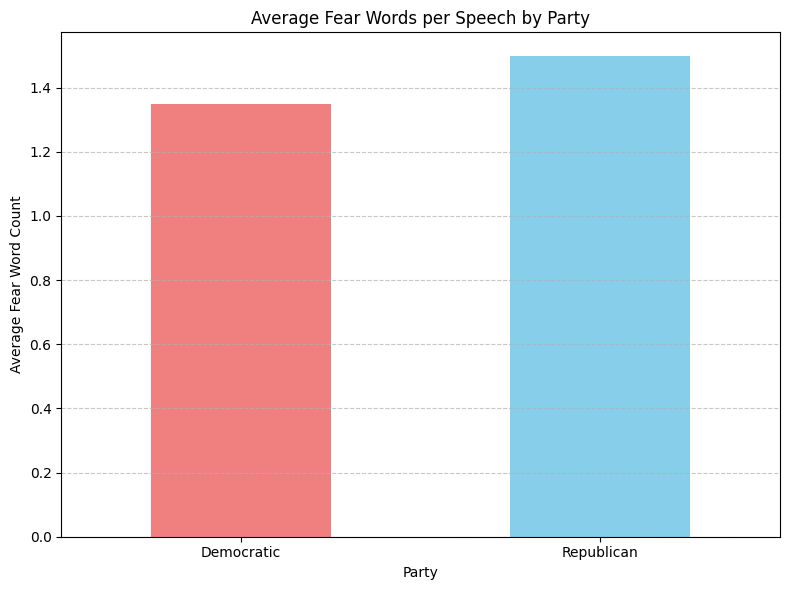

In [ ]:
# Activity 3a: Bar chart of average fear words per speech by party
# Expected output: a bar chart with one bar per party

# Calculate average fear words per speech by party
fear_by_party = debates.groupby('Party')['fear_count'].mean()

# Create a bar chart
plt.figure(figsize=(8, 6))
fear_by_party.plot(kind='bar', color=['lightcoral', 'skyblue'])

# Add title and labels
plt.title('Average Fear Words per Speech by Party')
plt.xlabel('Party')
plt.ylabel('Average Fear Word Count')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 📝 Activity 3b: Top 10 Fear Words

Find the **10 most common fear-related words** across all speeches. Create a horizontal bar chart.

Steps:
1. Flatten all tokens into a DataFrame
2. Filter to only words in the fear set
3. Count occurrences with `value_counts()`
4. Plot the top 10

/tmp/ipykernel_1147/718271623.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='count', y='word', data=top_10_fear_words, palette='Reds_d')


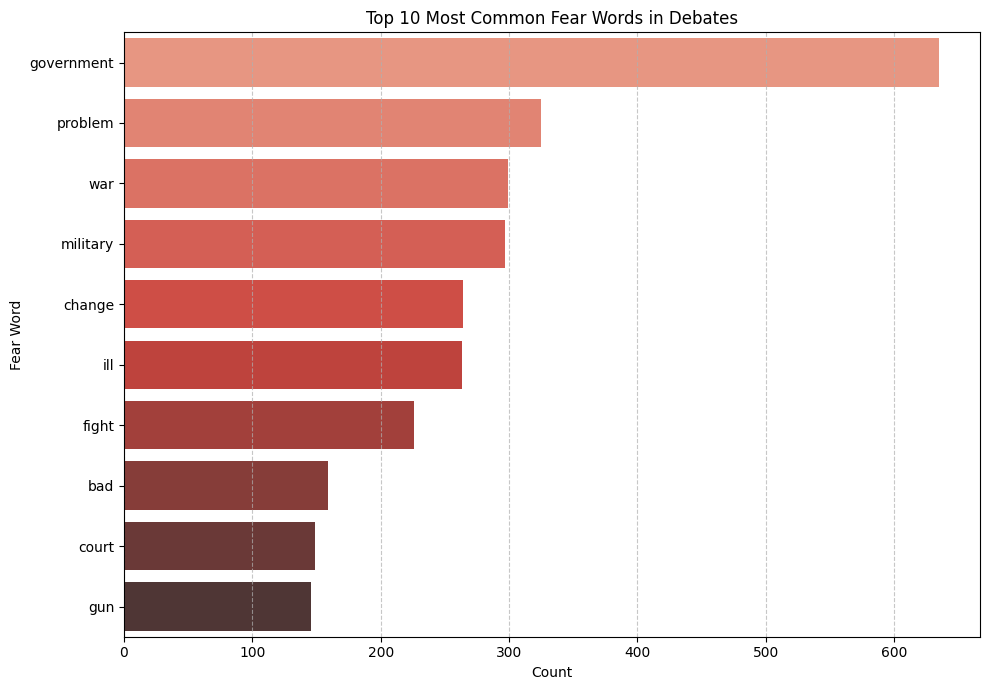

In [ ]:
# Activity 3b: Top 10 fear words in the debates
# Expected output: a horizontal bar chart of the 10 most common fear words

# 1. Flatten all tokens into a DataFrame (already done in all_tokens)
# 2. Filter to only words in the fear set
fear_words_in_debates = all_tokens[all_tokens['word'].isin(fear_set)]

# 3. Count occurrences with value_counts()
top_10_fear_words = fear_words_in_debates['word'].value_counts().head(10).reset_index()
top_10_fear_words.columns = ['word', 'count']

# 4. Plot the top 10
plt.figure(figsize=(10, 7))
sns.barplot(x='count', y='word', data=top_10_fear_words, palette='Reds_d')
plt.title('Top 10 Most Common Fear Words in Debates')
plt.xlabel('Count')
plt.ylabel('Fear Word')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

---
## Activity 4: Full Emotion Profile by Candidate (~15 min)

Build a **grouped bar chart** showing all 8 NRC emotions for Clinton vs. Trump.

### 📝 Activity 4a: Count All 8 Emotions for Clinton and Trump

For each of the 8 emotions (anger, anticipation, disgust, fear, joy, sadness, surprise, trust), count the average number of words per speech for Clinton and Trump. Then create a grouped bar chart.

Steps:
1. Define the 8 emotions as a list
2. For each emotion, build a word set and count matches per speech
3. Group by Speaker and compute means
4. Plot as a grouped bar chart

*Hint: Use a loop over the 8 emotion names to avoid repeating code*

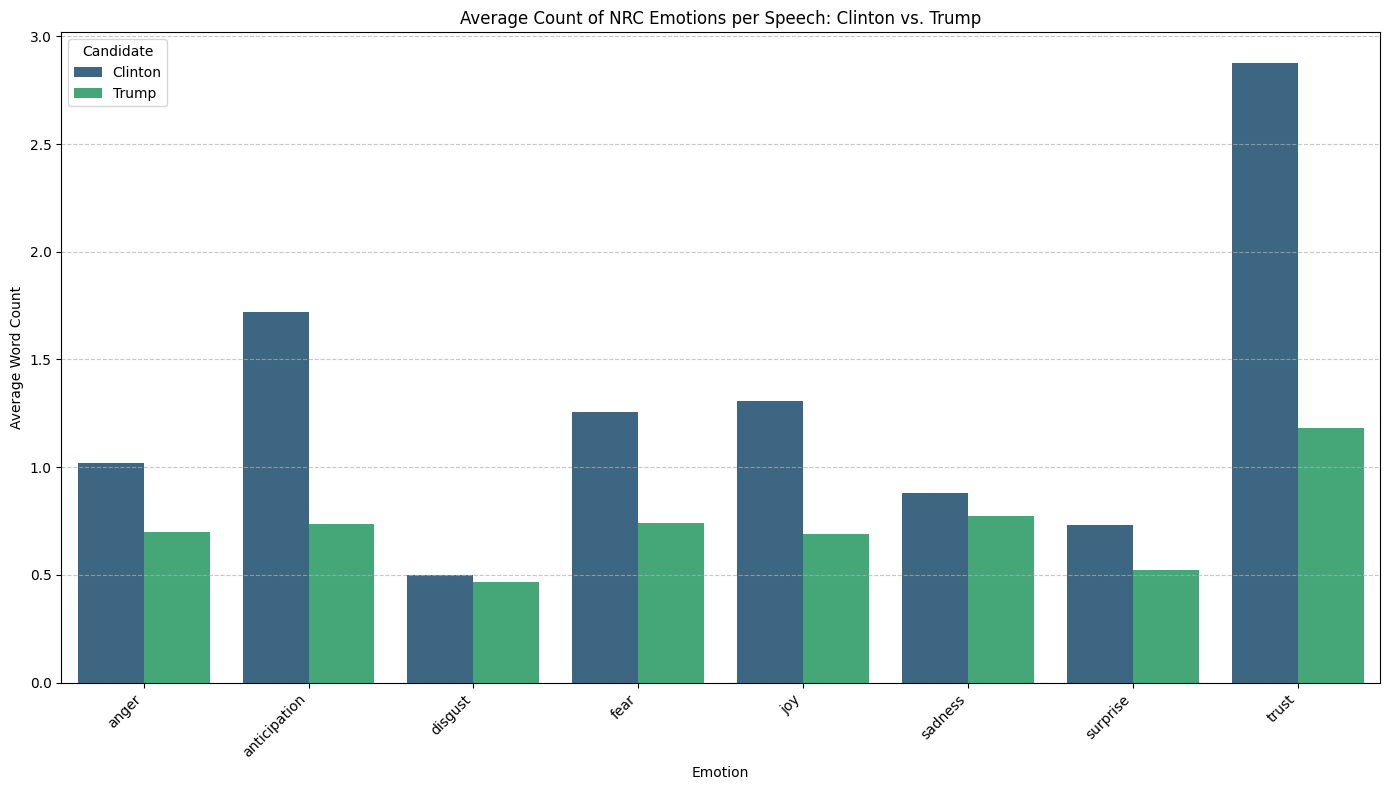

In [ ]:
# Activity 4a: Grouped bar chart of all 8 emotions for Clinton vs Trump
# Expected output: a grouped bar chart with one group per emotion,
#   each group containing two bars (Clinton, Trump)

# 1. Define the 8 emotions as a list
primary_emotions = ['anger', 'anticipation', 'disgust', 'fear', 'joy', 'sadness', 'surprise', 'trust']

# Ensure emotion count columns exist and are calculated for all speeches
# Create a copy of the debates DataFrame to avoid SettingWithCopyWarning
emo_debates = debates.copy()

for emotion in primary_emotions:
    # Build a word set for the current emotion
    emotion_set = set(nrc_df[nrc_df['emotion'] == emotion]['word'])

    # Count words for the current emotion in each speech
    # Only update if the column doesn't exist, to avoid recalculating unnecessarily
    if f'{emotion}_count' not in emo_debates.columns:
        emo_debates[f'{emotion}_count'] = emo_debates['tokens'].apply(
            lambda tokens: sum(1 for word in tokens if word in emotion_set))

# 2. Filter for Clinton and Trump
clinton_trump_emo_data = emo_debates[emo_debates['Speaker'].isin(['Clinton', 'Trump'])]

# 3. Group by Speaker and compute means for all emotion counts
avg_all_emotions_by_candidate = clinton_trump_emo_data.groupby('Speaker')[[f'{e}_count' for e in primary_emotions]].mean().reset_index()

# Reshape the data for plotting with seaborn
avg_all_emotions_melted = avg_all_emotions_by_candidate.melt(
    id_vars='Speaker',
    var_name='Emotion',
    value_name='Average Count'
)

# Clean up the emotion names for plotting (remove '_count')
avg_all_emotions_melted['Emotion'] = avg_all_emotions_melted['Emotion'].str.replace('_count', '')

# 4. Plot as a grouped bar chart
plt.figure(figsize=(14, 8)) # Wider figure to accommodate 8 emotion groups
sns.barplot(
    x='Emotion',
    y='Average Count',
    hue='Speaker',
    data=avg_all_emotions_melted,
    palette='viridis' # Choose a color palette
)

plt.title('Average Count of NRC Emotions per Speech: Clinton vs. Trump')
plt.xlabel('Emotion')
plt.ylabel('Average Word Count')
plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for readability
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Candidate')
plt.tight_layout()
plt.show()

### 📝 Activity 4b: Interpret the Emotion Profile

Look at your chart from 4a and answer:

1. Which emotions show the biggest difference between Clinton and Trump?
2. Which emotions are roughly similar for both candidates?
3. Based on the emotion profiles, how would you describe each candidate's rhetorical style in one sentence?



**Your answers here:**

1. Looking at the chart, 'trust' and 'anticipation' seem to show the biggest differences, with Clinton having significantly higher average counts for both compared to Trump. 'Joy' also shows a noticeable difference.

2. Emotions like 'disgust' and 'sadness' appear to be roughly similar for both candidates, with their average word counts being quite close

3. Based on the emotion profiles, Clinton's rhetorical style appears more optimistic and forward-looking, emphasizing trust and future expectations. Trump's style, while showing some fear, appears to be less overtly emotional across several positive categories compared to Clinton, with a relatively consistent level of negative emotions like disgust and sadness.

---
## Summary

Here's what you practiced in this notebook:

| Activity | Topic | Key Methods |
|----------|-------|-------------|
| 1a | Average sentiment by party | `opinion_lexicon`, `groupby().mean()` |
| 1b | Top sentiment words | `.merge()`, `sns.barplot()` |
| 1c | Interpret limitations | Critical thinking |
| 2a | Lexicon vs VADER comparison | `SentimentIntensityAnalyzer`, `.plot(kind='bar')` |
| 2b | VADER by candidate | `.isin()`, `groupby()` |
| 2c | Joy and fear by candidate | `NRCLex`, emotion word sets |
| 3a | Fear by party | Emotion counting |
| 3b | Top fear words | `value_counts()`, horizontal bar chart |
| 4a | Full emotion profile | Loop over emotions, grouped bar chart |
| 4b | Interpret emotion profiles | Critical thinking |

**Key takeaways:**
- Opinion Lexicon: simple word counting, transparent but context-blind
- VADER: handles negation and intensity, better accuracy
- NRC: maps words to 8 specific emotions for richer analysis
- Always use multiple methods and compare results!

---
## Reminders

- **Submit** this notebook via Canvas by the deadline.
- **Office hours**: Check the syllabus for times and location.
- **Project #2**: Make sure you are making progress on your unstructured data project. Reach out if you have questions!